In [1]:
%reset -f

import numpy as np
import pandas as pd
import torch
from pathlib import Path

import sys
sys.path.append("../../tools")
import prepare as prep
import functions as func
import generation as gr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(gr)
#importlib.reload(prep)
#importlib.reload(func)


In [3]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis labels (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick labels (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

cmap = LinearSegmentedColormap.from_list(
    "custom_cmap",
    ["#f4f4f4", "#FCB00C"]
)


In [4]:
load_dir1 = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r9")
load_dir2 = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r1")
load_dir3 = Path(f"../../saved_models/num_stable_states_15fold/sp3to20_NS_transpt3_r7")
load_dir4 = Path(f"../../saved_models/fluctuation_15fold_v2/sp3to20_Fl_transpt3_r1")
load_dir5 = Path(f"../../saved_models/swi_species_15fold/sp3to20_SS_transpt3_r13")
emodel = func.load_saved_model_MD(load_dir1, device)
dmodel = func.load_saved_model_MD(load_dir2, device)
nmodel = func.load_saved_model_NS(load_dir3, device)
fmodel = func.load_saved_model_MD(load_dir4, device)
smodel = func.load_saved_model_SS(load_dir5, device)
epredictor = func.Predictor(emodel)
dpredictor = func.Predictor(dmodel)
npredictor = func.Predictor(nmodel)
fpredictor = func.Predictor(fmodel)
spredictor = func.Predictor(smodel)

MaxNum = dpredictor.ckpt["NumSpecies"]


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [9]:
def get_Xnum(df, pick_list, n_real):
    '''
    pick_list: list of species to be picked, e.g. [0, 3, 13]
    '''
    X_mu = [1 for i in range(n_real)]
    #X_mu = 0.2 + 0.8*np.random.rand(n_real)
    X_D = [0 for i in range(n_real)]
    all_gamma = -np.array(df)
    gamma = all_gamma[np.ix_(pick_list, pick_list)]

    X_gamma = []
    for i in range(n_real):
        for j in range(n_real):
            if i!=j:
                X_gamma.append(gamma[i, j]/abs(gamma[j, j]))

    Xnum = np.concatenate((X_mu, X_gamma, X_D))
    return Xnum, gamma


In [3]:
sup2 = pd.read_csv("supdata2.csv", delimiter=";")

In [10]:
sup1 = pd.read_csv("supdata1.csv", delimiter=";")
sup1 = sup1[sup1["number_of_carbons"].isin([1, 8, 16])]
cols = sup1.columns[-14:]
for col in cols:
    sup1[col] = pd.to_numeric(
        sup1[col].astype(str)
        .str.replace(",", ".", regex=False)
        .str.replace("E+", "E-", regex=False),
        errors="coerce"
    )
array = sup1.iloc[:, -14:].values
row_sum = array.sum(axis=1)
mask = (row_sum>0.9) & (row_sum<1.1)
sup1 = sup1.loc[mask, :]


In [11]:
sp_ini_cols = sup1.columns[1:15]
resources_list = [
    pd.read_pickle("Bayes_1carb.pkl"),
    pd.read_pickle("Bayes_8carb.pkl"),
    pd.read_pickle("Bayes_16carb.pkl"),
]


In [12]:
results = []

# Initial community classification
for cidx, sub_df in sup1.groupby(list(sp_ini_cols)):

    # cidx is a tuple of 14 0/1 values
    # Find present species and convert to 0-13 indices
    pick_list = [i for i, x in enumerate(cidx) if x == 1]
    n_real = len(pick_list)

    # Exclude edge cases
    if n_real == 0:
        continue

    # Resource count classification
    for ridx, subsub_df in sub_df.groupby("number_of_carbons"):

        # Select resource matrix
        if ridx == 1:
            resources = resources_list[0]
        elif ridx == 8:
            resources = resources_list[1]
        elif ridx == 16:
            resources = resources_list[2]
        else:
            continue

        # Community index check
        community_index_list = subsub_df["community_index"].unique()

        if len(community_index_list) != 1:
            print(
                "Warning: multiple community_index:",
                community_index_list
            )

        community_index = community_index_list[0]

        Xnum, gamma = get_Xnum(resources, pick_list, n_real)
        #Xynum = gr.predict_numerical(Xnum, n_real, repeat=200, timespan=np.arange(0,800.1,.1))
        
        Xnum_pad = prep.pad_Xnum_to_maxspecies(Xnum, n_real, MaxNum)
        dpred = float(dpredictor.predict_array_MD(Xnum_pad, device=device))
        epred = float(epredictor.predict_array_MD(Xnum_pad, device=device))
        npred = int(npredictor.predict_array_NS(Xnum_pad, device))
        fpred = int(fpredictor.predict_array_Fl(Xnum_pad, device, 0.2))
        spred = spredictor.predict_array_SS(Xnum_pad, device)

        # Last 14 columns correspond to species abundances
        MeanAbun = subsub_df.iloc[:, -14:].mean(axis=0).values
        Abun = subsub_df.iloc[:, -14:].values

        # Keep only present species
        MeanAbun = MeanAbun[pick_list]
        MeanAbun = MeanAbun * abs(np.diag(gamma))
        dtrue = gr.Calculate_Entropy(n_real, MeanAbun)

        Abun = Abun[:, pick_list]
        Abun = Abun * abs(np.diag(gamma))
        Index = gr.Calculate_Index(Abun.shape[0], Abun, thresh1=0.05)
        AbunTot = gr.Calculate_Proportion(Index)
        etrue = gr.Calculate_Entropy(n_real, AbunTot)

        # Save results
        results.append({
            "dpred": dpred,
            "dtrue": dtrue,
            "epred": epred,
            "npred": npred,
            "fpred": fpred,
            #"spred": spred,
            #"dsim": Xynum[0, n_real**2 + n_real + 2],
            "resources_num": ridx,
            "community_index": community_index,
            "n_real": n_real,
        })

df_result = pd.DataFrame(results)


C:\Users\HW\AppData\Local\Temp\ipykernel_21564\3610335384.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  dpred = float(dpredictor.predict_array_MD(Xnum_pad, device=device))
C:\Users\HW\AppData\Local\Temp\ipykernel_21564\3610335384.py:44: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  epred = float(epredictor.predict_array_MD(Xnum_pad, device=device))
C:\Users\HW\AppData\Local\Temp\ipykernel_21564\3610335384.py:45: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  

In [5]:
df_result.to_csv(f"resource_all.csv", index=False)

NameError: name 'df_result' is not defined

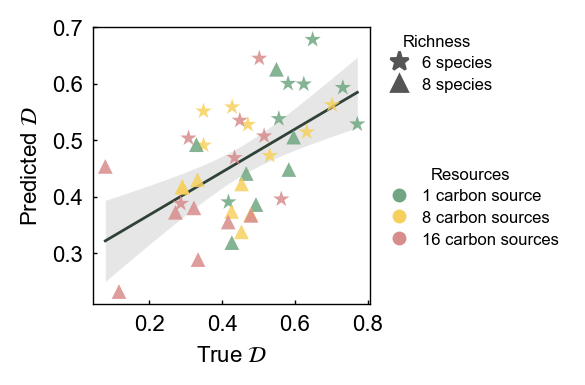

slope = 0.3801
intercept = 0.2914
R² = 0.3164
Regression p-value = 0.0001058
Spearman's r = 0.5611, p-value = 0.0001107
Pearson's r = 0.5625, p-value = 0.0001058


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import linregress, t, spearmanr, pearsonr
from datetime import datetime

sub_result = pd.read_csv("resource_all.csv")

# Extract data, ensure numeric type
plotx = pd.to_numeric(sub_result["dtrue"], errors="coerce").to_numpy(dtype=float)
ploty = pd.to_numeric(sub_result["dpred"], errors="coerce").to_numpy(dtype=float)
richness = pd.to_numeric(sub_result["n_real"], errors="coerce").to_numpy(dtype=float)
resources = pd.to_numeric(sub_result["resources_num"], errors="coerce").to_numpy(dtype=float)

# Synchronous filtering so shape, color and coords stay aligned
mask = (
    np.isfinite(plotx)
    & np.isfinite(ploty)
    & np.isfinite(richness)
    & np.isfinite(resources)
)

x = plotx[mask]
y = ploty[mask]
richness = richness[mask].astype(int)
resources = resources[mask].astype(int)

if len(x) < 3:
    raise ValueError("Insufficient valid points for linear regression")

# Linear regression: use all valid data points
result = linregress(x, y)

slope = result.slope
intercept = result.intercept
r_value = result.rvalue
p_value = result.pvalue
stderr = result.stderr

# Fit line
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = intercept + slope * x_fit

# 95% confidence interval for regression mean
n = len(x)
df = n - 2
alpha = 0.05

t_crit = t.ppf(1 - alpha / 2, df)
x_mean = np.mean(x)
Sxx = np.sum((x - x_mean) ** 2)

residuals = y - (intercept + slope * x)
residual_std = np.sqrt(np.sum(residuals**2) / df)

se_fit = residual_std * np.sqrt(
    1 / n + (x_fit - x_mean) ** 2 / Sxx
)

ci_upper = y_fit + t_crit * se_fit
ci_lower = y_fit - t_crit * se_fit


# ==========================================================
# Plotting
# ==========================================================

# Color represents resource count
resource_colors = {
    1: "#70A782",
    8: "#F6D05E",
    16: "#D98C8C",
}

# Shape represents community richness
richness_markers = {
    6: "*",
    8: "^",
}

# Reserve space on right for two separate legends
fig, ax = plt.subplots(figsize=(2.8, 1.8), dpi=200)
fig.subplots_adjust(right=0.62)

# 95% confidence band
ax.fill_between(
    x_fit,
    ci_lower,
    ci_upper,
    alpha=0.5,
    linewidth=0,
    color="#cfcfcf",
    zorder=1,
)

# Regression line
ax.plot(
    x_fit,
    y_fit,
    color="#2f4236",
    linewidth=1,
    zorder=2,
)

# Draw scatter by richness and resource count
for richness_value, marker in richness_markers.items():
    for resource_value, color in resource_colors.items():

        group = (
            (richness == richness_value)
            & (resources == resource_value)
        )

        if not np.any(group):
            continue

        ax.scatter(
            x[group],
            y[group],
            marker=marker,
            s=38 if richness_value == 6 else 28,
            color=color,
            alpha=0.85,
            edgecolors="none",
            zorder=3,
        )

# Legend 1: community richness (shape)
shape_handles = [
    Line2D(
        [], [],
        marker="*",
        linestyle="none",
        color="#555555",
        markersize=7,
        label="6 species",
    ),
    Line2D(
        [], [],
        marker="^",
        linestyle="none",
        color="#555555",
        markersize=6,
        label="8 species",
    ),
]

legend1 = ax.legend(
    handles=shape_handles,
    title="Richness",
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    frameon=False,
    fontsize=6,
    title_fontsize=6,
    handletextpad=0.4,
    labelspacing=0.4,
    borderaxespad=0,
)

ax.add_artist(legend1)

# Legend 2: resource count (color)
resource_handles = [
    Line2D(
        [], [],
        marker="o",
        linestyle="none",
        markerfacecolor=color,
        markeredgecolor="none",
        markersize=5,
        label=f"{r} carbon source" if r == 1
              else f"{r} carbon sources",
    )
    for r, color in resource_colors.items()
]

ax.legend(
    handles=resource_handles,
    title="Resources",
    loc="upper left",
    bbox_to_anchor=(1.02, 0.52),
    frameon=False,
    fontsize=6,
    title_fontsize=6,
    handletextpad=0.4,
    labelspacing=0.4,
    borderaxespad=0,
)

# Axes
ax.set_xlabel(r"True $\mathcal{D}$")
ax.set_ylabel(r"Predicted $\mathcal{D}$")
ax.tick_params(direction="in")

plt.savefig(
    f"scatter2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

plt.show()

spear, spear_p = spearmanr(x, y)
pear, pear_p = pearsonr(x, y)

print(f"slope = {slope:.4g}")
print(f"intercept = {intercept:.4g}")
print(f"R² = {r_value**2:.4f}")
print(f"Regression p-value = {p_value:.4g}")
print(f"Spearman's r = {spear:.4f}, p-value = {spear_p:.4g}")
print(f"Pearson's r = {pear:.4f}, p-value = {pear_p:.4g}")


Spearman's rho: 0.11952029819301516, p-value: 0.4509015006611091
Pearson's r: 0.18682548326835824, p-value: 0.23613854024782005
r2: -5458.528163820213


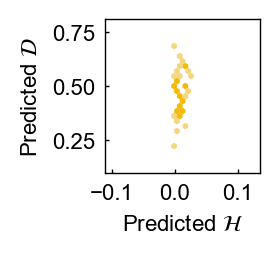

In [9]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
from datetime import datetime
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import r2_score

cmap = LinearSegmentedColormap.from_list(
    "custom_cmap",
    ["#f3f3f3", "#F5BA09"]
)

#sub_result = df_result[df_result["resources_num"]==1]
#sub_result = df_result[df_result["n_real"]==6]
#sub_result = df_result
sub_result = pd.read_csv("resource_all.csv")

plotx = sub_result["epred"].values
ploty = sub_result["dpred"].values
# plotx = sub_result["dtrue"].values
# ploty = sub_result["dpred"].values
# plotx = sub_result["etrue"].values
# ploty = sub_result["epred"].values

# Scale to [0, 1]
# plotx = (plotx - plotx.min()) / (plotx.max() - plotx.min())
# ploty = (ploty - ploty.min()) / (ploty.max() - ploty.min())

# Standardize
# plotx = (plotx - plotx.mean()) / plotx.std()
# ploty = (ploty - ploty.mean()) / ploty.std()

plt.figure(figsize=(1,1), dpi=200)

hb = plt.hexbin(
    plotx,
    ploty,
    gridsize=25, # number of hexagons
    extent=(plotx.min()-0.1, plotx.max()+0.1, ploty.min()-0.1, ploty.max()+0.1),   # xmin, xmax, ymin, ymax
    mincnt=1, # minimum count in each hexagon
    cmap=cmap,
    vmin=0,
    vmax=2, # maximum count in each hexagon
    edgecolors='none',
    # alpha=0.8,
    rasterized=True
)

spear, spear_p = spearmanr(plotx, ploty)
pear, pear_p = pearsonr(plotx, ploty)
r2 = r2_score(plotx, ploty)

print(f"Spearman's rho: {spear}, p-value: {spear_p}")
print(f"Pearson's r: {pear}, p-value: {pear_p}")
print(f"r2: {r2}")

# cbar = plt.colorbar(hb)
# cbar.set_label("Count")

# plt.xlim(-0.1, 1.1)
# plt.ylim(-0.1, 1.1)
plt.xlabel(r"Predicted $\mathcal{H}$")
plt.ylabel(r"Predicted $\mathcal{D}$")
# plt.xlabel(r"Ture $\mathcal{D}$")
# plt.ylabel(r"Predicted $\mathcal{D}$")
plt.tick_params(direction='in')
#plt.savefig(f"R2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf", dpi=1000, bbox_inches='tight')
plt.show()


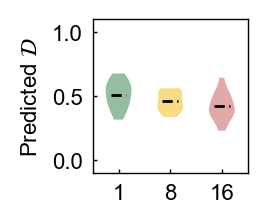

(<Figure size 200x200 with 1 Axes>, <Axes: ylabel='Predicted $\\mathcal{D}$'>)

In [15]:
from datetime import datetime
def plot_discrete_violin(data1, data2, data3, figsize=(1, 1), save_path=None):

    data = [data1, data2, data3]
    positions = [0, 1, 2]

    colors = [
        "#70A782",
        "#F6D05E",
        "#D98C8C"
    ]

    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    vp = plt.violinplot(
        data,
        positions=positions,
        widths=0.5,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    # violin color
    for body, color in zip(vp['bodies'], colors):
        body.set_facecolor(color)
        body.set_edgecolor('none')
        body.set_alpha(0.75)

    # mean line
    means = [np.mean(d) for d in data]

    for x, m in zip(positions, means):
        plt.hlines(
            m,
            x - 0.15,
            x + 0.15,
            color='black',
            linewidth=1,
            linestyle='--',
            zorder=5
        )

    # x-axis
    plt.xticks(
        positions,
        ['1', '8', '16']
    )

    plt.ylabel(r"Predicted $\mathcal{D}$")

    # Axes
    ax.tick_params(direction="in")

    for spine in ax.spines.values():
        spine.set_color("black")

    plt.grid(False)

    # x-range for each of the three groups
    plt.xlim(-0.5, 2.5)

    # survival fraction
    plt.ylim(-0.1, 1.1)

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=1000,
            bbox_inches='tight',
            transparent=True
        )

    plt.show()

    return fig, ax

sub_result = df_result
data1 = sub_result[sub_result["resources_num"]==1]["dpred"].values
data2 = sub_result[sub_result["resources_num"]==8]["dpred"].values
data3 = sub_result[sub_result["resources_num"]==16]["dpred"].values

plot_discrete_violin(data1, data2, data3, figsize=(1, 1), 
                     save_path=f"violin_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf")
